In [30]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,classification_report


In [2]:
df = pd.read_csv(r"C:\Users\shiwangi\OneDrive\Desktop\ML project@\Credit_card_fraud_detection_ML_project\dataset\creditcard.csv")

# df.head()
# df.info()

df.drop(columns=['Time'], axis=1, inplace=True)
df.columns


Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')

In [3]:
print(df['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
print(df.describe())

                 V1            V2            V3            V4            V5  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15  9.604066e-16   
std    1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00  1.380247e+00   
min   -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00 -1.137433e+02   
25%   -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01 -6.915971e-01   
50%    1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02 -5.433583e-02   
75%    1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01  6.119264e-01   
max    2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01  3.480167e+01   

                 V6            V7            V8            V9           V10  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15  2.239053e-15   
std    1.332271e+00  1.237094e+00  1.194353e+00  1.

In [12]:
legit = df[df['Class'] == 0]

fruad = df[df['Class'] == 1]


print(fruad.head(10))

            V1        V2        V3        V4        V5        V6        V7  \
541  -2.312227  1.951992 -1.609851  3.997906 -0.522188 -1.426545 -2.537387   
623  -3.043541 -3.157307  1.088463  2.288644  1.359805 -1.064823  0.325574   
4920 -2.303350  1.759247 -0.359745  2.330243 -0.821628 -0.075788  0.562320   
6108 -4.397974  1.358367 -2.592844  2.679787 -1.128131 -1.706536 -3.496197   
6329  1.234235  3.019740 -4.304597  4.732795  3.624201 -1.357746  1.713445   
6331  0.008430  4.137837 -6.240697  6.675732  0.768307 -3.353060 -1.631735   
6334  0.026779  4.132464 -6.560600  6.348557  1.329666 -2.513479 -1.689102   
6336  0.329594  3.712889 -5.775935  6.078266  1.667359 -2.420168 -0.812891   
6338  0.316459  3.809076 -5.615159  6.047445  1.554026 -2.651353 -0.746579   
6427  0.725646  2.300894 -5.329976  4.007683 -1.730411 -1.732193 -3.968593   

            V8        V9       V10  ...       V21       V22       V23  \
541   1.391657 -2.770089 -2.772272  ...  0.517232 -0.035049 -0.46521

In [38]:
new_df = legit.sample(n=492)

new_dataset = pd.concat([new_df, fraud], axis=0)

print(new_dataset.shape)

(984, 30)


In [22]:
X = new_dataset.drop(columns=['Class'], axis=1)
y = new_dataset['Class']

In [39]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1, stratify=y)
print(y_train.head(10))

141122    0
241254    1
42674     1
6820      1
252774    1
110405    0
63405     0
2930      0
228242    0
124236    0
Name: Class, dtype: int64


In [42]:
print(X_train.shape)
print(X_test.shape)

print(y_train.value_counts())
print(y_test.value_counts())

(787, 29)
(197, 29)
Class
0    394
1    393
Name: count, dtype: int64
Class
1    99
0    98
Name: count, dtype: int64


In [45]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=2000)

In [46]:
# Predict on test data
Y_pred = model.predict(X_test)

In [48]:
y_pred=model.predict(X_test)
#print(y_pred)
print(type(y_pred))

<class 'numpy.ndarray'>


In [49]:
accuracy = accuracy_score(y_test, y_pred)

print(f'Model Accuracy: {accuracy * 100:.2f}%')

Model Accuracy: 91.88%


In [50]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92        98
           1       0.95      0.89      0.92        99

    accuracy                           0.92       197
   macro avg       0.92      0.92      0.92       197
weighted avg       0.92      0.92      0.92       197



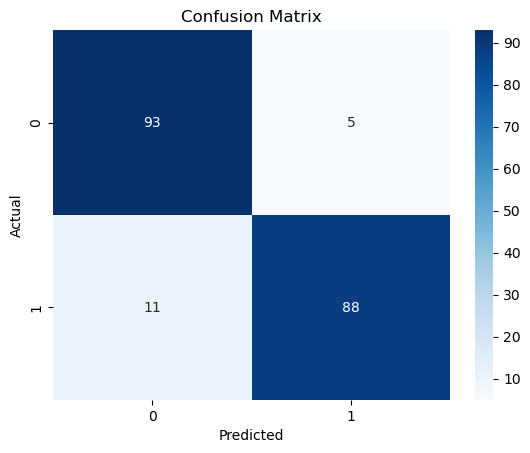

In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [54]:
import pickle

with open('fraud_model.pkl', 'wb') as file:
    pickle.dump(model, file)